# 1. Exploration et nettoyage des données

Objectif : explorer le dataset *Approach to Social Media Cyberbullying and Harassment
Detection Using Advanced Machine Learning* (`data/raw/`), comprendre sa structure,
le nettoyer, puis sauvegarder une version prête à être chargée dans MongoDB (étape 2).

Le fichier contient 3 colonnes :
- **Text** : le message brut (issu de réseaux sociaux)
- **Label** : `Bullying` / `Not-Bullying`, mais saisi avec de très nombreuses variantes
  d'écriture (espaces, casse, tirets, fautes de frappe)
- **Types** : sous-catégorie du harcèlement (`Sexual`, `Religion`, `Ethnicity`,
  `Threats`, `Political`, `Vocational`, `Troll`, ...), renseignée uniquement pour les
  lignes `Bullying`, elle aussi avec des variantes/fautes de frappe

## Import des librairies

In [3]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", 120)
sns.set_style("whitegrid")

## Chargement du dataset brut (data/raw/)

In [4]:
RAW_PATH = "../data/raw/Approach to Social Media Cyberbullying and Harassment Detection Using Advanced Machine Learning.csv"

df = pd.read_csv(RAW_PATH)
df.shape

(8452, 3)

## Exploration initiale (shape, types, valeurs manquantes, distribution brute)

In [5]:
df.head()

,Text,Label,Types
0,Ten outside soon doctor shake everyone treatment seat radio land.,Not-Bullying,NaN
1,my life has come to a standstill and at this point.,Not-Bullying,NaN
2,girl this nigga make me sick to my stomach,Bullying,Ethnicity
3,I wanna fuck you,Bullying,Sexual
4,"Oh hey, you should be ashamed of your disgusting self",Not - Bullying,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8452 entries, 0 to 8451
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    8452 non-null   object
 1   Label   8450 non-null   object
 2   Types   4825 non-null   object
dtypes: object(3)
memory usage: 198.2+ KB


In [ ]:
# Valeurs manquantes par colonne
df.isna().sum()

Text        0
Label       2
Types    3627
dtype: int64

##### NB : "Types" est vide pour la plupart des lignes "Not-Bullying" -> normal, pas un problème de qualité

In [ ]:
df["Label"].value_counts(dropna=False)

Label
Bullying          3020
Not-Bullying      2752
Bullying          1805
Not- Bullying      270
Not-Bullying       252
Not Bullying       242
Not-Bulllying       31
Not-Bulying         30
Not-Bulyying        21
Not - Bullying       5
Not -Bullying        4
Not -Bullying        4
Not bullying         4
Bullying.            3
Bullyinfg            3
NaN                  2
Not- Bullying        1
Bullyiing            1
Bullying             1
Bullyibg             1
Name: count, dtype: int64

##### La colonne "Label" contient énormément de variantes du même libellé (espaces, casse, tirets, fautes de frappe) -> il faudra la normaliser.

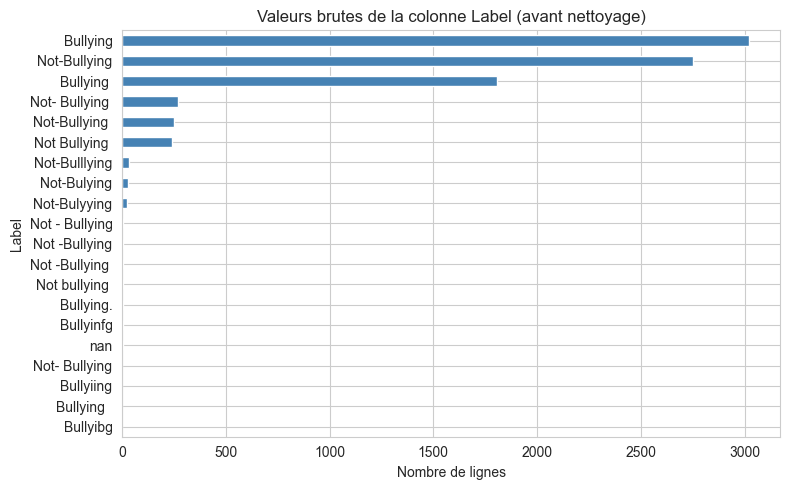

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
df["Label"].value_counts(dropna=False).plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Valeurs brutes de la colonne Label (avant nettoyage)")
ax.set_xlabel("Nombre de lignes")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

##### Visualisation : on voit clairement qu'il s'agit d'une seule variable binaire éclatée en une vingtaine de variantes d'écriture différentes

In [11]:
df["Types"].value_counts(dropna=False)

Types
NaN            3627
Sexual          987
Troll           948
Political       734
Vocational      670
Religion        649
Threat          193
Ethnicity       169
Threats         157
Vocational       79
Religion         48
Religon          45
Sexual           36
Ethnicity        31
Threats          23
Political        20
Religious        10
Troll             7
sexual            6
Racism            4
political         3
Saxual            2
Vocation          2
Ethnically        1
Threat            1
Name: count, dtype: int64

##### Idem pour "Types" : renseigné seulement pour les lignes "Bullying", avec ses propres variantes/fautes (ex: 'Religon', 'Threat' vs 'Threats', 'Saxual', ...)

In [12]:
# Doublons exacts sur le texte brut
n_dup = df["Text"].duplicated().sum()
print(f"Nombre de textes dupliqués : {n_dup} sur {len(df)} lignes")

# Longueur des textes (en mots) avant nettoyage
raw_len = df["Text"].astype(str).str.split().str.len()
raw_len.describe()

Nombre de textes dupliqués : 2472 sur 8452 lignes


count    8452.000000
mean        9.476455
std         4.654357
min         1.000000
25%         6.000000
50%         9.000000
75%        12.000000
max        52.000000
Name: Text, dtype: float64

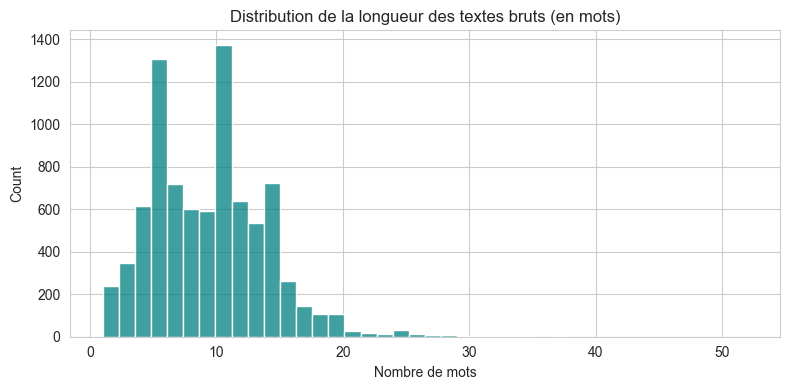

In [13]:
# Distribution de la longueur des textes (en mots)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(raw_len, bins=40, ax=ax, color="teal")
ax.set_title("Distribution de la longueur des textes bruts (en mots)")
ax.set_xlabel("Nombre de mots")
plt.tight_layout()
plt.show()

## Nettoyage

In [14]:
df_clean = df.copy()


def normalize_label(label):
    """Ramène toutes les variantes ('Bullying ', 'Not - Bullying', 'Not-Bulllying', ...)
    à deux classes propres : 'Bullying' / 'Not-Bullying'."""
    if pd.isna(label):
        return np.nan
    flat = re.sub(r"[^a-z]", "", str(label).lower())
    if not flat:
        return np.nan
    return "Not-Bullying" if "not" in flat else "Bullying"


df_clean["Label"] = df_clean["Label"].apply(normalize_label)
df_clean["Label"].value_counts(dropna=False)

Label
Bullying        4834
Not-Bullying    3616
NaN                2
Name: count, dtype: int64

In [15]:
# Correction des fautes de frappe/variantes de la sous-catégorie "Types"
TYPES_MAP = {
    "religon": "Religion",
    "religious": "Religion",
    "religion": "Religion",
    "sexual": "Sexual",
    "saxual": "Sexual",
    "ethnicity": "Ethnicity",
    "ethnically": "Ethnicity",
    "racism": "Ethnicity",
    "threat": "Threats",
    "threats": "Threats",
    "vocational": "Vocational",
    "vocation": "Vocational",
    "political": "Political",
    "troll": "Troll",
}


def normalize_type(value):
    if pd.isna(value):
        return np.nan
    flat = str(value).strip().lower()
    if not flat:
        return np.nan
    return TYPES_MAP.get(flat, str(value).strip().title())


df_clean["Types"] = df_clean["Types"].apply(normalize_type)

# "Types" n'a de sens que pour les contenus de harcèlement -> "Aucun" pour Not-Bullying
df_clean.loc[df_clean["Label"] == "Not-Bullying", "Types"] = "Aucun"
df_clean["Types"] = df_clean["Types"].fillna("Non précisé")

df_clean["Types"].value_counts(dropna=False)

Types
Aucun          3616
Sexual         1028
Troll           955
Political       757
Religion        745
Vocational      744
Threats         373
Ethnicity       205
Non précisé      29
Name: count, dtype: int64

In [16]:
URL_RE = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
NON_ALNUM_RE = re.compile(r"[^a-z0-9\s']")
MULTISPACE_RE = re.compile(r"\s+")


def clean_text(text):
    """Nettoyage NLP standard : minuscules, suppression des URLs/mentions,
    normalisation des accents, ponctuation et espaces multiples."""
    if pd.isna(text):
        return ""
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode("utf-8")
    text = text.lower()
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(r"\1", text)
    text = NON_ALNUM_RE.sub(" ", text)
    text = MULTISPACE_RE.sub(" ", text).strip()
    return text


df_clean["Text"] = df_clean["Text"].astype(str).str.strip()
df_clean["text_clean"] = df_clean["Text"].apply(clean_text)
df_clean[["Text", "text_clean"]].head(10)

,Text,text_clean
0,Ten outside soon doctor shake everyone treatment seat radio land.,ten outside soon doctor shake everyone treatment seat radio land
1,my life has come to a standstill and at this point.,my life has come to a standstill and at this point
2,girl this nigga make me sick to my stomach,girl this nigga make me sick to my stomach
3,I wanna fuck you,i wanna fuck you
4,"Oh hey, you should be ashamed of your disgusting self",oh hey you should be ashamed of your disgusting self
5,Haha isn't route running part of the position? People are dumb. But fuck edelman! He just looks like he says,haha isn't route running part of the position people are dumb but fuck edelman he just looks like he says
6,Racism is when u select yur white clothes to wash first before the black and colored ones,racism is when u select yur white clothes to wash first before the black and colored ones
7,Who are islamists? Those who fully follow the teachings of Muhammed found in the Quran and Hadiths,who are islamists those who fully follow the teachings of muhammed found in the quran and hadiths
8,Male action movies...ehhhh @That_Damn_Ram Not sexist but female action movies...ehhhh,male action movies ehhhh not sexist but female action movies ehhhh
9,Wishing my arena partner was on.,wishing my arena partner was on


In [ ]:
label_counts_per_text = df_clean.groupby("text_clean")["Label"].nunique()
contradictory_texts = label_counts_per_text[label_counts_per_text > 1].index

print(f"Textes avec des labels contradictoires : {len(contradictory_texts)}")
df_clean[df_clean["text_clean"].isin(contradictory_texts)].sort_values("text_clean")[
    ["text_clean", "Label"]
].head(10)

Textes avec des labels contradictoires : 98


,text_clean,Label
7289,accept this chance with confidence you're up to the task,Not-Bullying
7044,accept this chance with confidence you're up to the task,Bullying
7080,accept this chance with confidence you're up to the task,Bullying
6887,answer my questions you moron verses from the qur'an that mention all muslims going to hell were given to me,Not-Bullying
7134,answer my questions you moron verses from the qur'an that mention all muslims going to hell were given to me,Bullying
4967,at this moment my life has come to a complete standstill,Not-Bullying
4963,at this moment my life has come to a complete standstill,Bullying
6980,best wishes on your well earned success,Bullying
7321,best wishes on your well earned success,Not-Bullying
7226,best wishes on your well earned success,Not-Bullying


##### Doublons "contradictoires" : le même texte nettoyé apparaît avec des labels différents (Bullying pour une occurrence, Not-Bullying pour une autre). Ce sont des annotations incohérentes qui perturberaient l'entraînement -> à supprimer.

In [18]:
n_before = len(df_clean)

# On retire les textes contradictoires (impossible de trancher sur le vrai label)
df_clean = df_clean[~df_clean["text_clean"].isin(contradictory_texts)]

# Lignes sans label exploitable ou texte vide après nettoyage
df_clean = df_clean.dropna(subset=["Label"])
df_clean = df_clean[df_clean["text_clean"].str.len() > 0]

# Doublons exacts restants (même texte nettoyé + même label)
df_clean = df_clean.drop_duplicates(subset=["text_clean", "Label"]).reset_index(drop=True)

print(f"Lignes avant nettoyage : {n_before}")
print(f"Lignes après nettoyage : {len(df_clean)}")
print(f"Lignes supprimées      : {n_before - len(df_clean)}")

df_clean["Label"].value_counts(normalize=True)

Lignes avant nettoyage : 8452
Lignes après nettoyage : 5740
Lignes supprimées      : 2712


Label
Bullying        0.547038
Not-Bullying    0.452962
Name: proportion, dtype: float64

In [19]:
# Longueur du texte nettoyé (en mots) -> utile pour la modélisation (padding, TF-IDF)
# et pour repérer le bruit résiduel (textes à 1 seul mot, souvent peu informatifs)
df_clean["text_len"] = df_clean["text_clean"].str.split().str.len()

n_short = (df_clean["text_len"] <= 1).sum()
print(f"Textes d'un seul mot après nettoyage : {n_short}")
df_clean.loc[df_clean["text_len"] <= 1, ["Text", "text_clean", "Label"]].head(10)

Textes d'un seul mot après nettoyage : 32


,Text,text_clean,Label
116,Sexy,sexy,Bullying
331,Motherfuck,motherfuck,Bullying
409,Gorgeous,gorgeous,Not-Bullying
731,Motherfukcer,motherfukcer,Bullying
794,Lessbian,lessbian,Bullying
808,fuckig,fuckig,Bullying
832,“More.”,more,Bullying
1018,Captivating!,captivating,Not-Bullying
1043,"gold!""",gold,Not-Bullying
1125,Horny,horny,Bullying


##### On garde ces textes courts : une insulte d'un seul mot ("nigger", "slut", ...) reste un signal de harcèlement valide, ce n'est pas du bruit à supprimer ici.

In [21]:
df_clean["text_len"].describe()

count    5740.000000
mean        9.588328
std         4.748056
min         1.000000
25%         6.000000
50%         9.000000
75%        12.000000
max        52.000000
Name: text_len, dtype: float64

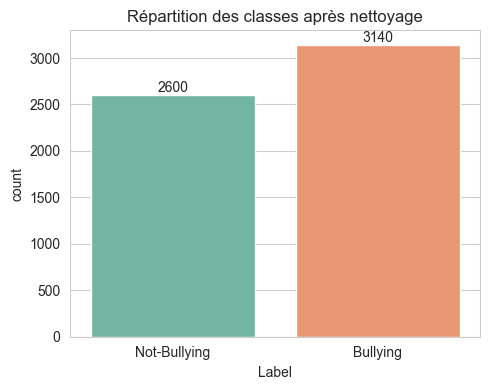

In [22]:
# Répartition finale Bullying / Not-Bullying 
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df_clean, x="Label", hue="Label", palette="Set2", legend=False, ax=ax)
ax.set_title("Répartition des classes après nettoyage")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

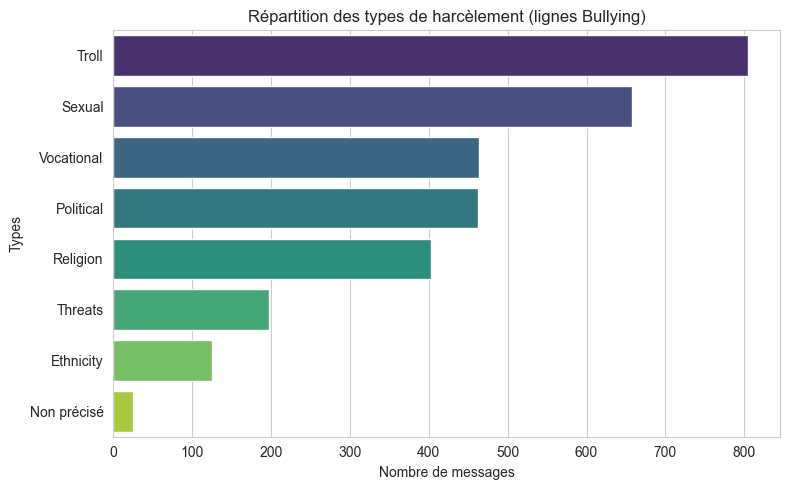

In [23]:
# Répartition des sous-catégories de harcèlement (hors "Aucun")
fig, ax = plt.subplots(figsize=(8, 5))
types_counts = df_clean.loc[df_clean["Types"] != "Aucun", "Types"].value_counts()
sns.barplot(x=types_counts.values, y=types_counts.index, hue=types_counts.index, palette="viridis", legend=False, ax=ax)
ax.set_title("Répartition des types de harcèlement (lignes Bullying)")
ax.set_xlabel("Nombre de messages")
plt.tight_layout()
plt.show()

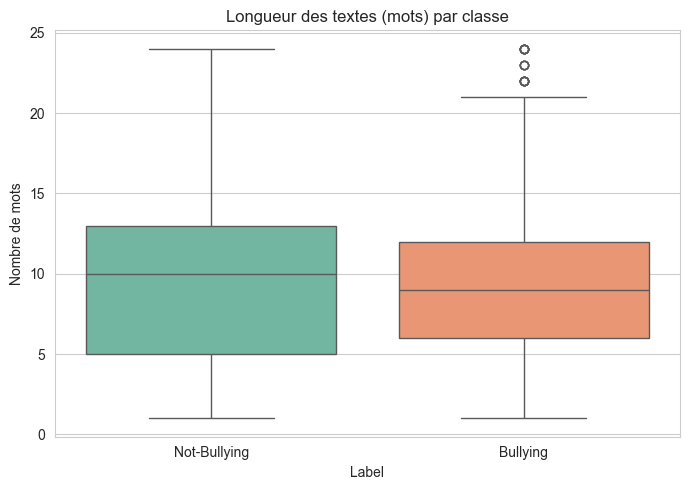

In [ ]:
# Longueur des textes selon la classe 
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df_clean[df_clean["text_len"] <= df_clean["text_len"].quantile(0.99)],
            x="Label", y="text_len", hue="Label", palette="Set2", legend=False, ax=ax)
ax.set_title("Longueur des textes (mots) par classe")
ax.set_ylabel("Nombre de mots")
plt.tight_layout()
plt.show()

In [25]:
from collections import Counter

STOPWORDS = {
    "the", "a", "an", "and", "or", "is", "are", "was", "were", "to", "of", "in",
    "on", "for", "it", "that", "this", "i", "you", "he", "she", "they", "we",
    "my", "your", "his", "her", "their", "our", "me", "him", "them", "us",
    "be", "been", "am", "so", "at", "as", "with", "not", "do", "does", "did",
    "have", "has", "had", "but", "just", "there", "than", "then", "s", "t",
}


def top_words(texts, n=15):
    counter = Counter()
    for text in texts:
        counter.update(w for w in text.split() if w not in STOPWORDS and len(w) > 1)
    return counter.most_common(n)


for label in ["Bullying", "Not-Bullying"]:
    print(f"--- Mots les plus fréquents ({label}) ---")
    for word, count in top_words(df_clean.loc[df_clean["Label"] == label, "text_clean"]):
        print(f"{word:15s} {count}")
    print()

--- Mots les plus fréquents (Bullying) ---
you're          300
can             207
political       159
religious       150
like            140
religion        131
i'm             128
post            128
if              126
should          106
by              100
humor           89
about           88
all             85
comedy          82

--- Mots les plus fréquents (Not-Bullying) ---
like            200
you're          162
love            159
it's            146
world           124
content         124
i'm             123
beauty          123
videos          119
channel         118
every           113
keep            109
positivity      107
make            103
life            100



In [26]:
df_clean.head(10)

,Text,Label,Types,text_clean,text_len
0,Ten outside soon doctor shake everyone treatment seat radio land.,Not-Bullying,Aucun,ten outside soon doctor shake everyone treatment seat radio land,10
1,my life has come to a standstill and at this point.,Not-Bullying,Aucun,my life has come to a standstill and at this point,11
2,girl this nigga make me sick to my stomach,Bullying,Ethnicity,girl this nigga make me sick to my stomach,9
3,I wanna fuck you,Bullying,Sexual,i wanna fuck you,4
4,"Oh hey, you should be ashamed of your disgusting self",Not-Bullying,Aucun,oh hey you should be ashamed of your disgusting self,10
5,Haha isn't route running part of the position? People are dumb. But fuck edelman! He just looks like he says,Bullying,Ethnicity,haha isn't route running part of the position people are dumb but fuck edelman he just looks like he says,20
6,Racism is when u select yur white clothes to wash first before the black and colored ones,Bullying,Ethnicity,racism is when u select yur white clothes to wash first before the black and colored ones,17
7,Who are islamists? Those who fully follow the teachings of Muhammed found in the Quran and Hadiths,Bullying,Religion,who are islamists those who fully follow the teachings of muhammed found in the quran and hadiths,17
8,Male action movies...ehhhh @That_Damn_Ram Not sexist but female action movies...ehhhh,Bullying,Religion,male action movies ehhhh not sexist but female action movies ehhhh,11
9,Wishing my arena partner was on.,Not-Bullying,Aucun,wishing my arena partner was on,6


## Sauvegarde des données nettoyées (data/processed/)

In [27]:
OUTPUT_PATH = "../data/processed/cyberbullying_clean.csv"

df_final = df_clean[["Text", "text_clean", "Label", "Types", "text_len"]]
df_final.to_csv(OUTPUT_PATH, index=False)

print(f"Fichier sauvegardé : {OUTPUT_PATH}")
print(f"Shape finale : {df_final.shape}")

Fichier sauvegardé : ../data/processed/cyberbullying_clean.csv
Shape finale : (5740, 5)
